In [3]:
from ultralytics import YOLO

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
import numpy as np
import pandas as pd
import json

In [6]:
from tqdm import tqdm
import os
from PIL import Image

In [7]:
model_26m = YOLO('yolo26m.pt')

In [ ]:
metrics_coco_val = model_26m.val(
    data='../data/validation/coco.yaml', 
    conf=0.25,
    save=False,
    device='cpu', 
    verbose=False,
    plots=True
)

"metrics_coco_val = model_26m.val(\n    data='../data/validation/coco.yaml', \n    conf=0.25,\n    save=False,\n    device='cpu', \n    verbose=False,\n    plots=True\n)"

In [ ]:
np.save("../outputs/detector/cm_coco.npy", metrics_coco_val.confusion_matrix.matrix)
np.save("../outputs/detector/ap_coco_por_clase.npy", metrics_coco_val.box.maps)
with open("../outputs/detector/metricas_coco.json", "w") as f:
    json.dump(metrics_coco_val.results_dict, f, indent=2)

In [ ]:
print("mAP50-95:", metrics_coco_val.box.map, "| mAP50:", metrics_coco_val.box.map50)
print("AP del gato:", metrics_coco_val.box.maps[15])

mAP50-95: 0.46562574096461723 | mAP50: 0.6069272007672575
AP del gato: 0.7596326553211041


In [ ]:
cm_coco_val = np.load("../outputs/detector/cm_coco.npy")
maps_coco_val = np.load("../outputs/detector/ap_coco_por_clase.npy")
with open("../outputs/detector/metricas_coco.json") as f:
    res_coco_val = json.load(f)

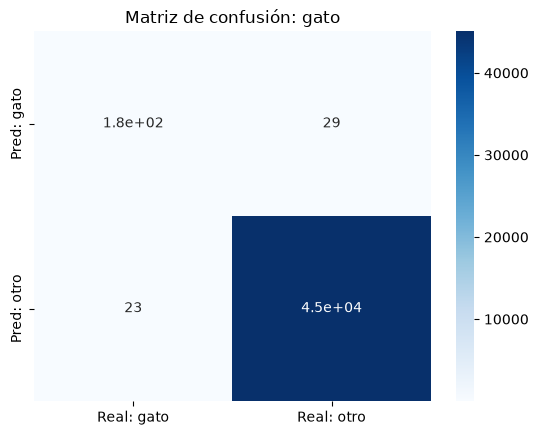

Precisión: 0.861 | Recall: 0.886


In [ ]:
c = 15                              
bg_coco_val = cm_coco_val.shape[0] - 1                           

TP_coco_val = cm_coco_val[c, c]
FP_coco_val = cm_coco_val[c, :].sum() - TP_coco_val
FN_coco_val = cm_coco_val[:, c].sum() - TP_coco_val
TN_coco_val = cm_coco_val.sum() - TP_coco_val - FP_coco_val - FN_coco_val

cm_cat_coco_val = np.array([[TP_coco_val, FP_coco_val],
                   [FN_coco_val, TN_coco_val]]) 

sns.heatmap(cm_cat_coco_val, annot=True, cmap='Blues',
            xticklabels=['Real: gato', 'Real: otro'],
            yticklabels=['Pred: gato', 'Pred: otro'])
plt.title('Matriz de confusión COCO VAL 2017: gato')
plt.show()

print(f"Precisión: {TP_coco_val/(TP_coco_val+FP_coco_val):.3f} | Recall: {TP_coco_val/(TP_coco_val+FN_coco_val):.3f}")

**VALIDACIÓN MUESTRA 300**

In [5]:
metrics_muestra_300 = model_26m.val(
    data='../data/validation/muestra_300.yaml', 
    conf=0.25,
    save=False,
    device='cpu', 
    verbose=False,
    plots=True
)

Ultralytics 8.4.176  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-12450H)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 252.1±84.9 MB/s, size: 192.2 KB)
val: Scanning C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\muestra_300... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 429.8it/s 0.7s0.1s
val: New cache created: C:\Users\castr\OneDrive\Desktop\proyecto_ia\data\validation\muestra_300.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.8s/it 1:325.1sss
                   all        300        307       0.99      0.983      0.983      0.844
Speed: 0.8ms preprocess, 291.2ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\detect\val-3


In [ ]:
np.save("../outputs/detector/cm_muestra_300.npy", metrics_muestra_300.confusion_matrix.matrix)
np.save("../outputs/detector/ap_por_clase_muestra_300.npy", metrics_muestra_300.box.maps)
with open("../outputs/detector/metricas_muestra_300.json", "w") as f:
    json.dump(metrics_muestra_300.results_dict, f, indent=2)

In [7]:
print("mAP50-95:", metrics_muestra_300.box.map, "| mAP50:", metrics_muestra_300.box.map50)
print("AP del gato:", metrics_muestra_300.box.maps[15])

mAP50-95: 0.8438700693969337 | mAP50: 0.9830114704375188
AP del gato: 0.8438700693969337


In [ ]:
cm_muestra_300 = np.load("../outputs/detector/cm_muestra_300.npy")
maps_muestra_300 = np.load("../outputs/detector/ap_por_clase_muestra_300.npy")
with open("../outputs/detector/metricas_muestra_300.json") as f:
    res = json.load(f)

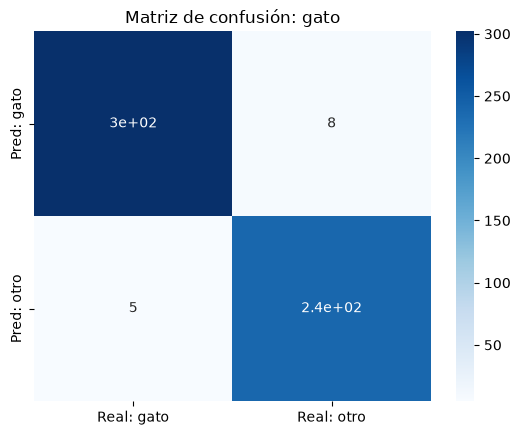

Precisión: 0.974 | Recall: 0.984


In [9]:
c = 15                                           # cat
bg = cm_muestra_300.shape[0] - 1                             # última fila/columna = fondo

TP_muestra_300 = cm_muestra_300[c, c]
FP_muestra_300 = cm_muestra_300[c, :].sum() - TP_muestra_300    # predijo gato y no lo era
FN_muestra_300 = cm_muestra_300[:, c].sum() - TP_muestra_300    # era gato y no lo detectó
TN_muestra_300 = cm_muestra_300.sum() - TP_muestra_300 - FP_muestra_300 - FN_muestra_300

cm_cat_muestra_300 = np.array([[TP_muestra_300, FP_muestra_300],
                   [FN_muestra_300, TN_muestra_300]])   # TN no se muestra: no aporta para gatos

sns.heatmap(cm_cat_muestra_300, annot=True, cmap='Blues',
            xticklabels=['Real: gato', 'Real: otro'],
            yticklabels=['Pred: gato', 'Pred: otro'])
plt.title('Matriz de confusión: gato')
plt.show()

print(f"Precisión: {TP_muestra_300/(TP_muestra_300+FP_muestra_300):.3f} | Recall: {TP_muestra_300/(TP_muestra_300+FN_muestra_300):.3f}")

**ANALISIS RECORTE IMAGENES REID**

In [7]:
df_reid = pd.read_csv('../data/processed/df_cat_reid.csv')
df_reid_modified = df_reid.copy()

In [8]:
df_reid_modified.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54


In [9]:
rutas = df_reid_modified['file_path'].astype(str).tolist()
PROC_DET = str("../data/interim/")
LABELS_DET = "det_26m"
lote = 32

In [ ]:
for r in tqdm(range(0, len(rutas), lote)): 
    results_test_crop = model_26m.predict(
    source=rutas[r:r+lote], save=False, save_txt=True, save_conf=True, 
    classes=[15], exist_ok=True, conf=0.25,
    verbose=False, project=PROC_DET, name=LABELS_DET,
)

In [11]:
ids = list(set(df_reid_modified['dir_name']))
ids_int = set(df_reid_modified['dir_name'].astype(int))
miss_ids = sorted(set(range(1, len(ids) + 1)) - ids_int)

In [12]:
miss_ids

[32, 70, 74, 116, 118, 119, 192]

In [13]:
PATH_LABELS = "./runs/data/interim/det_26m/labels"
labels = [os.path.basename(f).split('.')[0] for f in os.scandir(PATH_LABELS) if os.path.basename(f).endswith('txt')]
cat_images = df_reid_modified['file_name'].tolist()

In [14]:
df_analysis = df_reid_modified.copy()

df_analysis['detected'] = df_analysis['file_name'].isin(labels).astype(int)

In [15]:
for id in tqdm(labels):
    file_name = f'{id}.txt'
    file_path = f'{PATH_LABELS}/{file_name}'
    try: 
        data = np.loadtxt(file_path)

        if data.size > 0:
            if data.ndim == 1:
                conf_prediction = data[-1]
            else:
                conf_prediction = 0.0
        else:
            conf_prediction = 0.0
    except Exception:
        conf_prediction = 0.0
    df_analysis.loc[df_analysis['file_name'] == id, 'conf'] = conf_prediction

100%|██████████| 12872/12872 [00:17<00:00, 723.34it/s]


In [16]:
df_analysis.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,detected,conf
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44,1,0.938555
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42,1,0.956232
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99,1,0.941404
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14,1,0.935295
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54,1,0.928888


In [21]:
df_analysis_to_save = df_analysis.loc[
    df_analysis['detected'] == 1, ['file_path', 'dir_name', 'file_name']]
df_analysis_to_save.to_csv(
    '../data/processed/df_cat_reid_cropped.csv', index=False
)

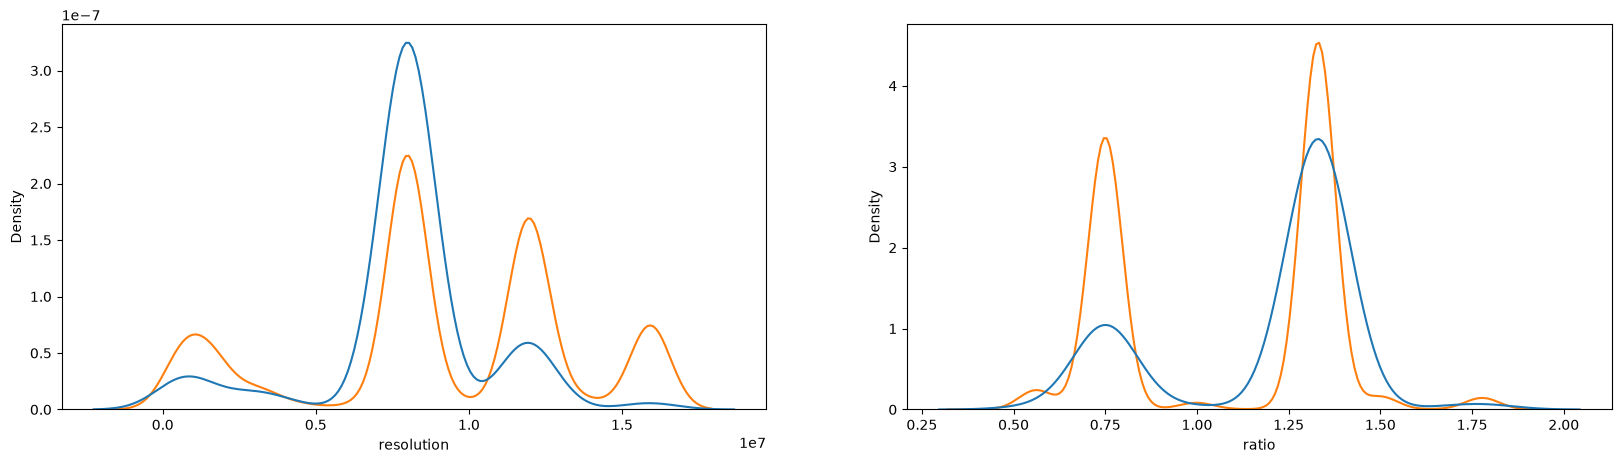

In [97]:
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)

sns.kdeplot(
    data=df_analysis, x='resolution', hue='detected', 
    alpha=1, legend=False, common_norm=False)

plt.subplot(1, 2, 2)
sns.kdeplot(
    data=df_analysis, x='ratio', hue='detected', 
    alpha=1, legend=False, common_norm=False)

plt.show()

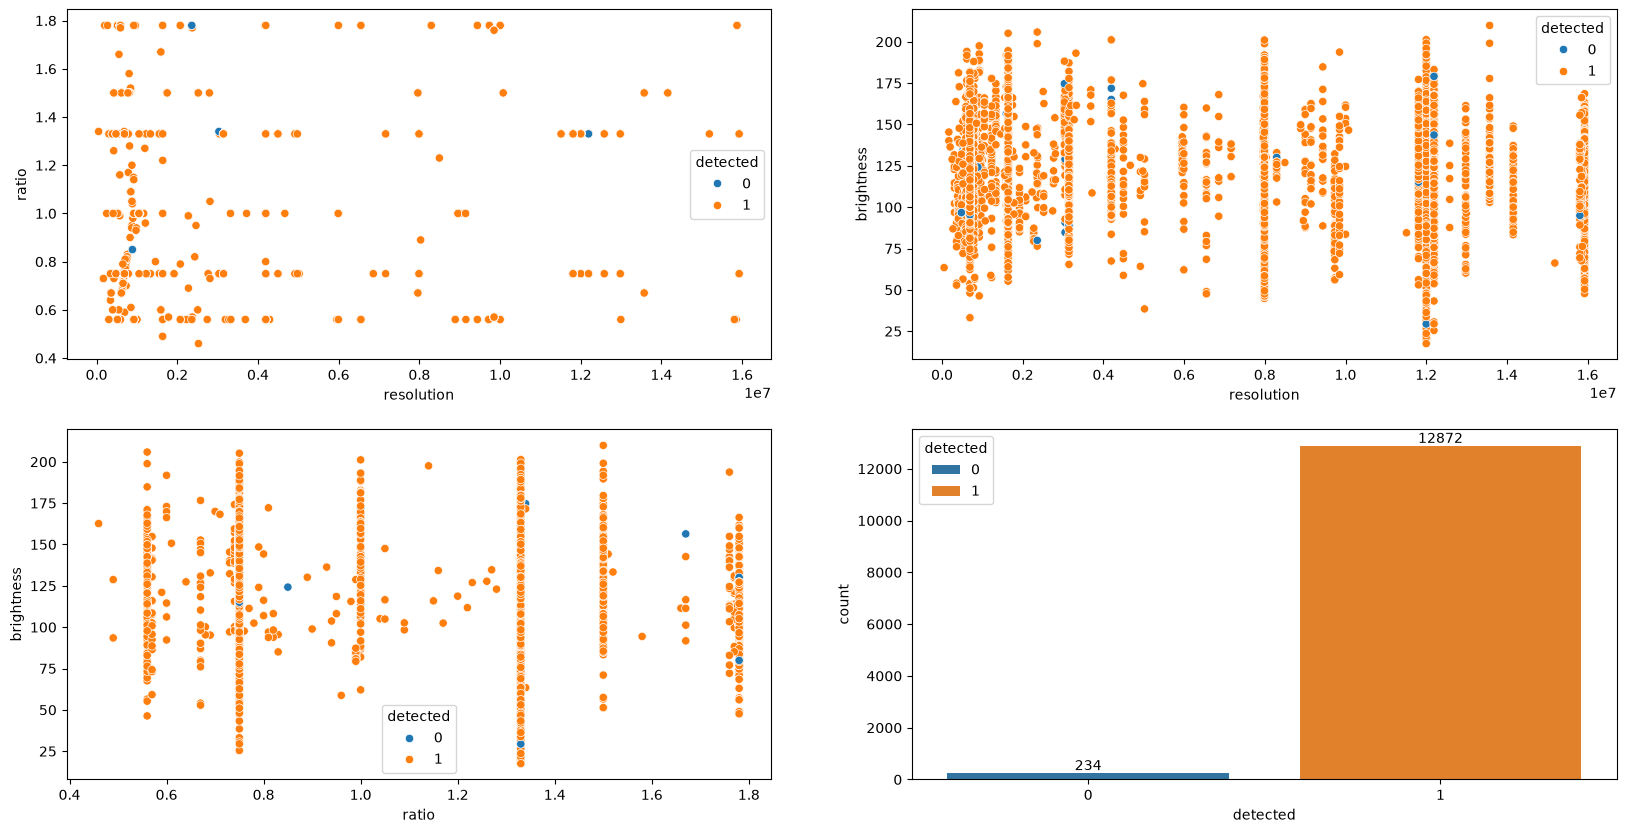

In [108]:
plt.figure(figsize=(20, 10))
plt.subplot(2, 2, 1)

sns.scatterplot(
    data=df_analysis, x='resolution', y='ratio',
    hue='detected', alpha=1)

plt.subplot(2, 2, 2)
sns.scatterplot(
    data=df_analysis, x='resolution', y='brightness',
    hue='detected', alpha=1)

plt.subplot(2, 2, 3)
sns.scatterplot(
    data=df_analysis, x='ratio', y='brightness',
    hue='detected', alpha=1)

plt.subplot(2, 2, 4)
ax = sns.countplot(
    data=df_analysis, x='detected',
    hue='detected', alpha=1)

for container in ax.containers:
    ax.bar_label(container, fontsize=10)
plt.show()